1. Cleaning data, dropping NA values and configurating dataframe size.

In [1]:
import pandas as pd
sheet1_df = pd.read_csv('../data/retail2.csv',encoding='latin1',parse_dates=['InvoiceDate'])
sheet2_df = pd.read_csv('../data/retail.csv',encoding='latin1',parse_dates=['InvoiceDate'])
retail_df = pd.concat([sheet1_df,sheet2_df],ignore_index=True) #
clean_retail = retail_df.dropna()
clean_retail = clean_retail.astype({"Quantity":"int16","Price":"float32", "Customer ID":"int32","Country":"category"})
clean_retail.info(memory_usage='deep')
clean_retail

<class 'pandas.DataFrame'>
Index: 824364 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      824364 non-null  str           
 1   StockCode    824364 non-null  str           
 2   Description  824364 non-null  str           
 3   Quantity     824364 non-null  int16         
 4   InvoiceDate  824364 non-null  datetime64[us]
 5   Price        824364 non-null  float32       
 6   Customer ID  824364 non-null  int32         
 7   Country      824364 non-null  category      
dtypes: category(1), datetime64[us](1), float32(1), int16(1), int32(1), str(3)
memory usage: 166.5 MB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680,France


2. Business Calculations:

    2.1 Sum of income

    2.2 Highest sale per year and month

    2.3 Highest sale per days in week
    
    2.4 Highest sale per hour

In [5]:
# 2.1 Kreiranje kolone za ukupnu zaradu po stavci i štampanje ukupnog prihoda
clean_retail['TotalPrice'] = clean_retail['Price'] * clean_retail['Quantity']
print("TOTAL INCOME OF THE SHOP: ", clean_retail['TotalPrice'].sum())
print("----------------------------------")

# 2.2 Prihod po godini i mesecu
print("Total income per year and month:")
month_n_year = clean_retail.groupby([clean_retail['InvoiceDate'].dt.year, clean_retail['InvoiceDate'].dt.month])['TotalPrice'].sum().sort_values(ascending=False)
print(month_n_year)
print("---------------------------------")

# 2.3 Prihod po danima u nedelji (koristimo day_name() da se vide imena dana)
print("Total income per day of week:")
weekday = clean_retail.groupby(clean_retail['InvoiceDate'].dt.day_name())['TotalPrice'].sum().sort_values(ascending=False)
print(weekday)
print("---------------------------------")

# 2.4 Prihod po satima
hours = clean_retail.groupby(clean_retail['InvoiceDate'].dt.hour)['TotalPrice'].sum().sort_values(ascending=False)
print("Total income per hour:")
print(hours)

TOTAL INCOME OF THE SHOP:  1.6648292e+07
----------------------------------
Total income per year and month:
InvoiceDate  InvoiceDate
2010         11             1.134879e+06
2011         11             1.132408e+06
             10             9.746036e+05
2010         10             9.649898e+05
2011         9              9.314404e+05
2010         12             8.592274e+05
             9              7.810333e+05
2009         12             6.632721e+05
2011         5              6.482511e+05
2010         3              6.359965e+05
2011         8              6.163680e+05
             6              6.080131e+05
2010         8              5.872564e+05
2011         3              5.799646e+05
             7              5.742385e+05
2010         6              5.714599e+05
             7              5.627859e+05
             4              5.606350e+05
             5              5.599246e+05
             1              5.319529e+05
             2              4.893996e+05
2011 

2.A Plotting the result of the number 2 steps.

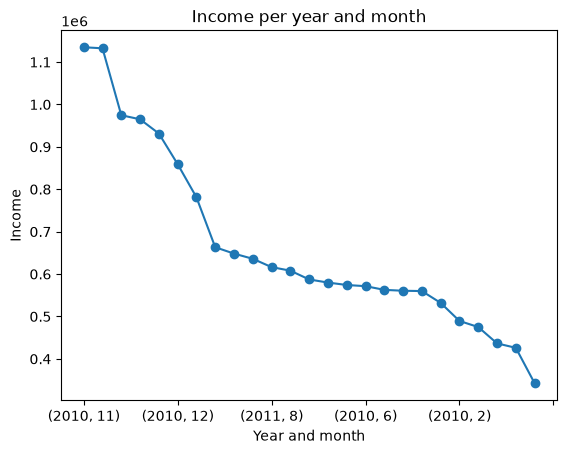

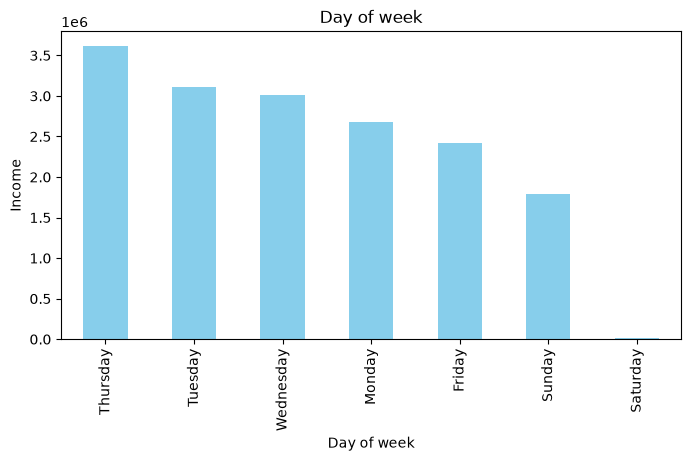

<Axes: title={'center': 'Income per hour in a day'}, xlabel='Hours', ylabel='Income'>

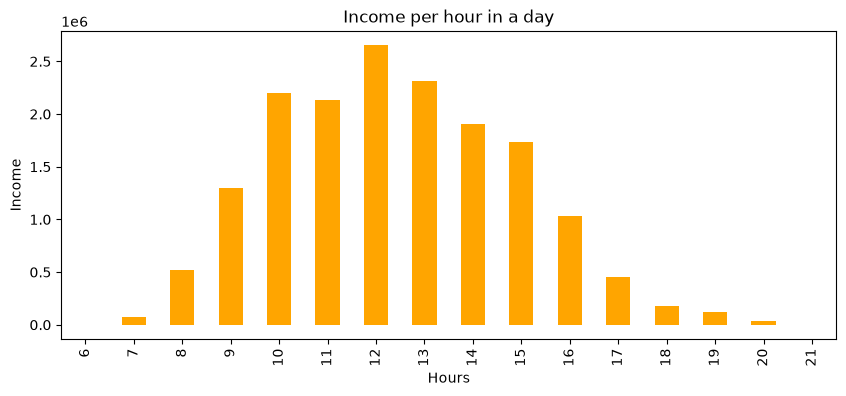

In [24]:
import matplotlib.pyplot as plt
month_n_year.plot(kind='line', marker='o', title="Income per year and month", xlabel="Year and month",ylabel="Income")
plt.show()
plt.figure(figsize=(8, 4))
weekday.plot(kind="bar",title="Day of week",ylabel="Income",color="skyblue",xlabel="Day of week")
plt.show()
plt.figure(figsize=(10, 4))
hours.sort_index().plot(kind="bar", title="Income per hour in a day", color="orange",ylabel="Income",xlabel="Hours")

3. Products analysis

        3.1 Sorting top 10 articles with most income

        3.2 Top 10 articles with highest selling quantity

        3.3. Visual display of articles